In [1]:
# ============================================================
# CELL 1 — Setup
# ============================================================

from pathlib import Path
import joblib, numpy as np, pandas as pd
import matplotlib.pyplot as plt
import networkx as nx

from PIL import Image
from scipy.optimize import linear_sum_assignment
from scipy.ndimage import label
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent

METRICS_DIR = ROOT / "metrics"
MODEL_DIR = ROOT / "models"
GRAPH_DIR = ROOT / "graph"
EXP_DIR = ROOT / "figures/exploratory"
EXP_DIR.mkdir(parents=True, exist_ok=True)

TARGETS = ["co","no2","o3","pm10","pm25","so2"]
MODELS = ["Ridge","Random Forest","XGBoost","MLP","GAT-LSTM"]

print("Visualization notebook ready.")

Visualization notebook ready.


In [2]:

# ============================================================
# CELL 2 — Load Final, Common-Window Results
# ============================================================

BASELINE_METRICS_DIR = METRICS_DIR / "baseline_fulltrain"

REGRESSION_PATH = (
    BASELINE_METRICS_DIR
    / "baseline_vs_gat_lstm_common_regression.csv"
)

AQI_METRICS_PATH = (
    BASELINE_METRICS_DIR
    / "baseline_vs_gat_lstm_common_aqi.csv"
)

AQI_WINDOWS_PATH = (
    BASELINE_METRICS_DIR
    / "common_aqi_windows_all_models.csv"
)

required_paths = [
    REGRESSION_PATH,
    AQI_METRICS_PATH,
    AQI_WINDOWS_PATH,
    MODEL_DIR / "gat_lstm_test_predictions.npy",
    MODEL_DIR / "gat_lstm_test_targets.npy",
    MODEL_DIR / "gat_lstm_test_mask.npy",
    MODEL_DIR / "gat_lstm_config.pkl",
]

for path in required_paths:
    if not path.exists():
        raise FileNotFoundError(
            f"Required final evaluation artifact not found:\n{path}"
        )

# Final regression results from Notebook 6, with identical
# eligible test rows for the five models for each pollutant.
reg_common = pd.read_csv(REGRESSION_PATH)

# Final AQI metrics from Notebook 6, using 84,014 shared windows.
aqi_common = pd.read_csv(AQI_METRICS_PATH)

# Exact station-time rows and actual/predicted categories used
# for the common AQI comparison.
aqi_windows = pd.read_csv(AQI_WINDOWS_PATH)

# Current GAT-LSTM artifacts saved by Notebook 7.
pred = np.load(
    MODEL_DIR / "gat_lstm_test_predictions.npy",
    allow_pickle=False,
)

true = np.load(
    MODEL_DIR / "gat_lstm_test_targets.npy",
    allow_pickle=False,
)

mask = np.load(
    MODEL_DIR / "gat_lstm_test_mask.npy",
    allow_pickle=False,
).astype(bool)

cfg = joblib.load(
    MODEL_DIR / "gat_lstm_config.pkl"
)

# Normalize column headers and model labels.
for df in [reg_common, aqi_common, aqi_windows]:
    df.columns = df.columns.str.strip()

reg_common["Model"] = reg_common["Model"].astype(str).str.strip()
aqi_common["Model"] = aqi_common["Model"].astype(str).str.strip()

# Split the pollutant results for the existing pollutant-wise
# heatmaps and charts below.
base_poll = reg_common[
    reg_common["Model"] != "GAT-LSTM"
].copy()

gat_poll = reg_common[
    reg_common["Model"] == "GAT-LSTM"
].copy()

# Basic integrity checks.
expected_models = set(MODELS)

if set(reg_common["Model"].unique()) != expected_models:
    raise ValueError(
        "Regression comparison does not contain exactly the expected "
        f"models. Found: {sorted(reg_common['Model'].unique())}"
    )

if len(reg_common) != len(MODELS) * len(TARGETS):
    raise ValueError(
        f"Expected {len(MODELS) * len(TARGETS)} model-pollutant results, "
        f"found {len(reg_common)}."
    )

if aqi_common["Model"].nunique() != len(MODELS):
    raise ValueError(
        "AQI metrics do not contain one result for every model."
    )

if len(aqi_windows) != 84014:
    raise ValueError(
        f"Expected 84,014 common AQI windows, found {len(aqi_windows):,}."
    )

if not (pred.shape == true.shape == mask.shape):
    raise ValueError(
        f"GAT-LSTM artifact shapes differ: "
        f"pred={pred.shape}, true={true.shape}, mask={mask.shape}"
    )

print("=" * 65)
print("FINAL VISUALIZATION INPUTS LOADED")
print("=" * 65)
print("Regression results:", reg_common.shape)
print("AQI model metrics:", aqi_common.shape)
print("Common AQI windows:", f"{len(aqi_windows):,}")
print("GAT-LSTM prediction shape:", pred.shape)
print("GAT-LSTM target shape:", true.shape)
print("Models:", sorted(reg_common["Model"].unique()))
print("Baseline metrics directory:", BASELINE_METRICS_DIR)


FINAL VISUALIZATION INPUTS LOADED
Regression results: (30, 6)
AQI model metrics: (5, 6)
Common AQI windows: 84,014
GAT-LSTM prediction shape: (6550, 37, 6)
GAT-LSTM target shape: (6550, 37, 6)
Models: ['GAT-LSTM', 'MLP', 'Random Forest', 'Ridge', 'XGBoost']
Baseline metrics directory: c:\Users\udish\College\MajorProjectSem7\Implementation\metrics\baseline_fulltrain


In [3]:

# ============================================================
# CELL 3 — Combine Final Regression and AQI Results
# ============================================================

# R² is unitless, so an unweighted mean across pollutant-specific
# test results is useful as a compact summary.
macro_r2 = (
    reg_common
    .groupby("Model", as_index=False)
    .agg(R2=("R2", "mean"))
)

macro_r2 = macro_r2.rename(
    columns={"R2": "Mean_Pollutant_R2"}
)

aqi_plot = aqi_common.rename(
    columns={
        "Macro_precision": "Precision",
        "Macro_recall": "Recall",
        "Macro_F1": "F1",
    }
)

summary = macro_r2.merge(
    aqi_plot[
        ["Model", "Accuracy", "Precision", "Recall", "F1"]
    ],
    on="Model",
    how="inner",
    validate="one_to_one",
)

# Keep model ordering consistent across all figures.
summary["_order"] = summary["Model"].map(
    {name: i for i, name in enumerate(MODELS)}
)

summary = (
    summary
    .sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)

if len(summary) != len(MODELS):
    raise ValueError(
        "The combined summary is missing one or more models."
    )

display(summary)

print(
    "\nMean_Pollutant_R2 is the unweighted mean of six "
    "pollutant-specific R² scores."
)
print(
    "AQI metrics use the common test windows from Notebook 6."
)


,Model,Mean_Pollutant_R2,Accuracy,Precision,Recall,F1
0,Ridge,0.869372,0.934630,0.917773,0.916513,0.917011
1,Random Forest,0.824137,0.862404,0.861410,0.735100,0.756249
2,XGBoost,0.873930,0.942557,0.942410,0.910228,0.924833
3,MLP,0.888960,0.938534,0.934672,0.912298,0.922392
4,GAT-LSTM,0.902225,0.957912,0.957895,0.939591,0.948343



Mean_Pollutant_R2 is the unweighted mean of six pollutant-specific R² scores.
AQI metrics use the common test windows from Notebook 6.


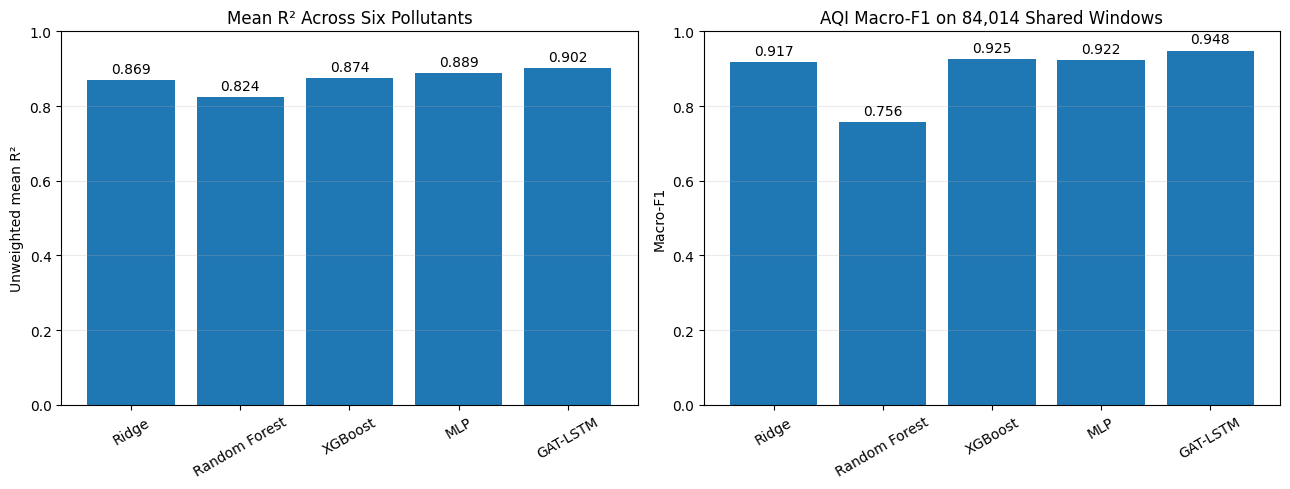

In [4]:

# ============================================================
# CELL 4 — Unitless Model Summary
# ============================================================

plot_summary = summary.set_index("Model").reindex(MODELS)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

metrics_to_plot = [
    (
        "Mean_Pollutant_R2",
        "Mean R² Across Six Pollutants",
        "Unweighted mean R²",
    ),
    (
        "F1",
        "AQI Macro-F1 on 84,014 Shared Windows",
        "Macro-F1",
    ),
]

for ax, (metric, title, ylabel) in zip(axes, metrics_to_plot):

    values = plot_summary[metric]
    bars = ax.bar(values.index, values.values)

    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_ylim(0, 1)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.25)

plt.tight_layout()

plt.savefig(
    EXP_DIR / "fig1_unitless_model_summary.png",
    dpi=400,
    bbox_inches="tight",
)

plt.show()


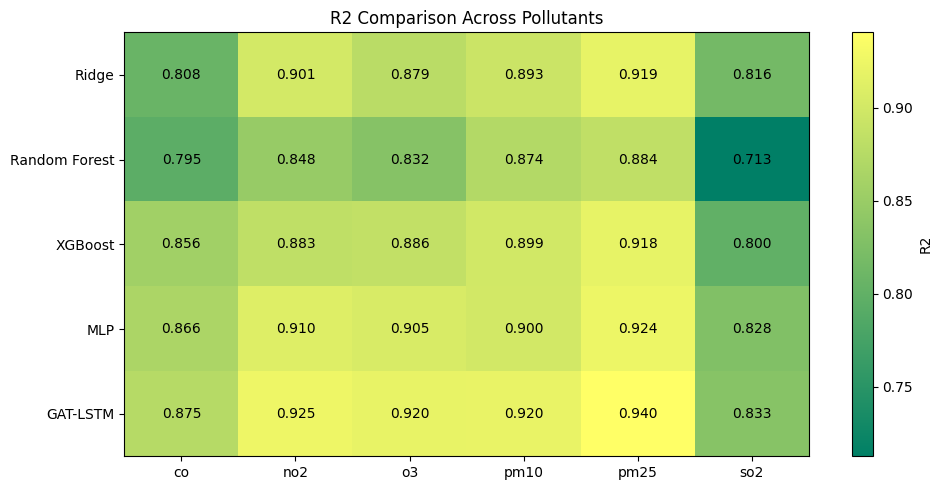

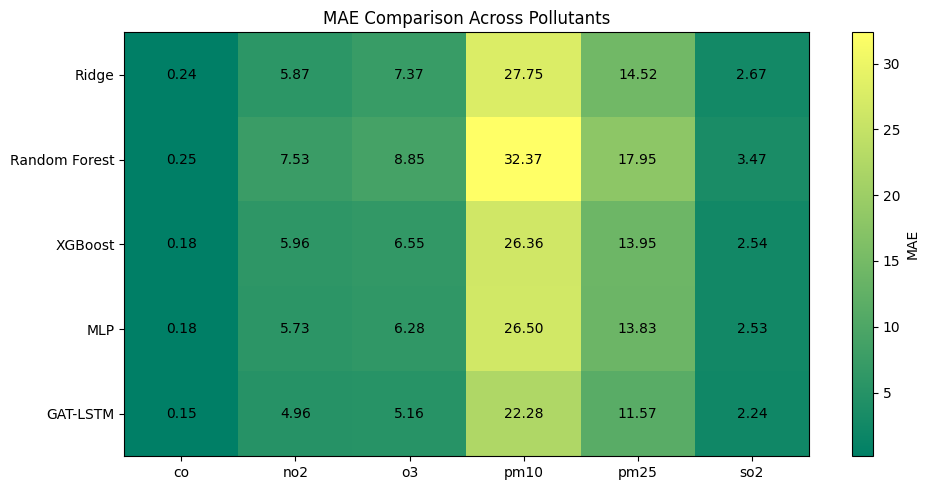

In [5]:
# ============================================================
# CELL 5 — R² + MAE Heatmaps
# ============================================================

def make_poll():
    a,g = base_poll.copy(),gat_poll.copy()
    a.columns = a.columns.str.strip(); g.columns = g.columns.str.strip()
    a = a.rename(columns={"model":"Model","target":"Pollutant","pollutant":"Pollutant","split":"Split"})
    g = g.rename(columns={"model":"Model","target":"Pollutant","pollutant":"Pollutant","split":"Split"})
    if "Split" in a: a = a[a.Split.str.lower()=="test"]
    if "Split" in g: g = g[g.Split.str.lower()=="test"]
    a = a[["Model","Pollutant","MAE","RMSE","R2"]]
    g = g[["Model","Pollutant","MAE","RMSE","R2"]]
    g["Model"] = "GAT-LSTM"
    return pd.concat([a,g]).drop_duplicates(["Model","Pollutant"])

poll = make_poll()

for metric,name in [("R2","fig2_r2_heatmap"),("MAE","fig3_mae_heatmap")]:
    tab = poll.pivot(index="Model",columns="Pollutant",values=metric).reindex(MODELS)[TARGETS]

    fig,ax = plt.subplots(figsize=(10,5))
    im = ax.imshow(tab.values,aspect="auto",cmap="summer")

    ax.set_xticks(range(6),TARGETS)
    ax.set_yticks(range(len(tab)),tab.index)
    ax.set_title(f"{metric} Comparison Across Pollutants")

    for i in range(tab.shape[0]):
        for j in range(tab.shape[1]):
            ax.text(j,i,f"{tab.iloc[i,j]:.3f}" if metric=="R2" else f"{tab.iloc[i,j]:.2f}",
                    ha="center",va="center")

    fig.colorbar(im,ax=ax,label=metric)
    plt.tight_layout()
    plt.savefig(EXP_DIR/f"{name}.png",dpi=400,bbox_inches="tight")
    plt.show()

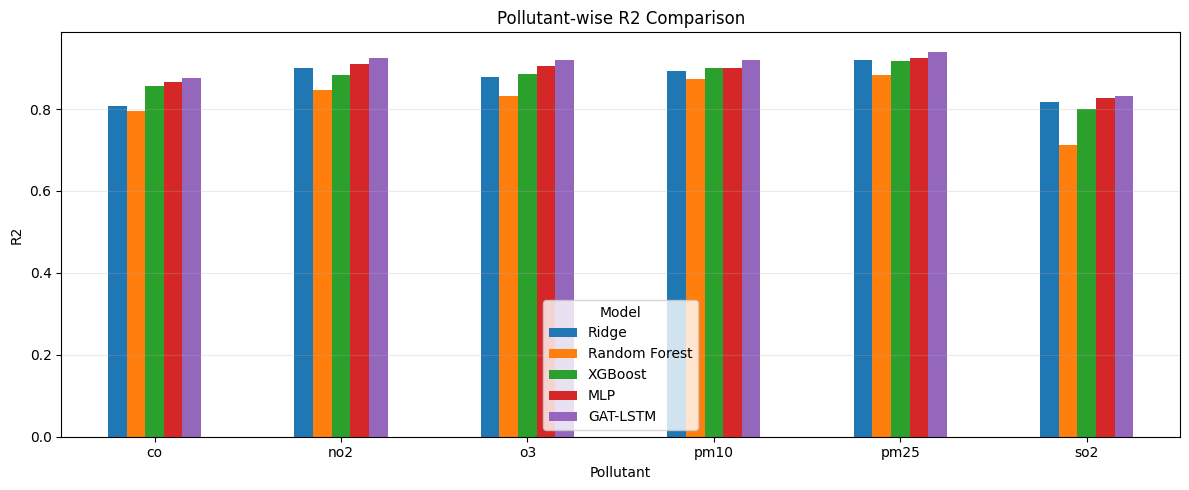

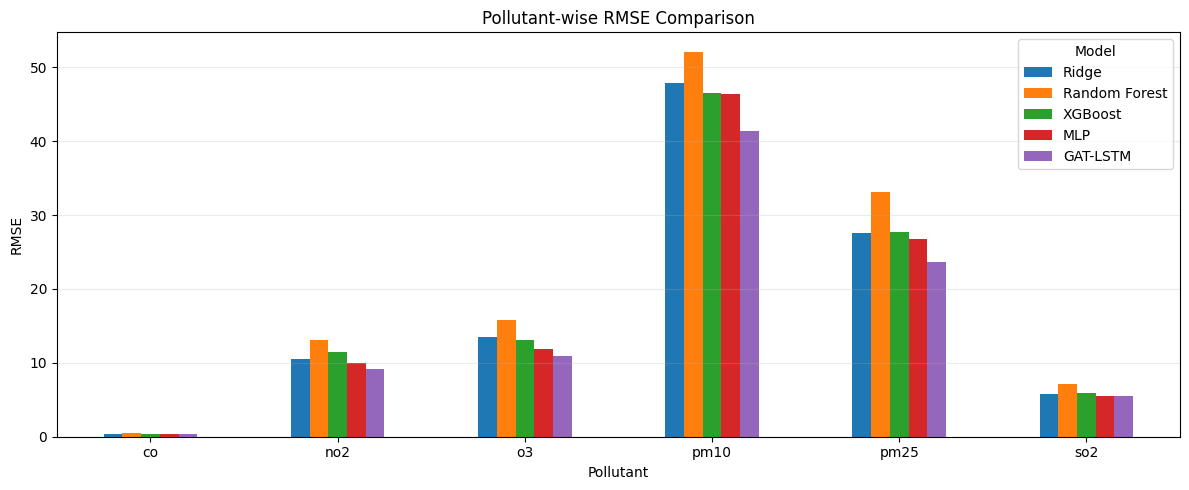

        Model Pollutant       MAE      RMSE       R2
        Ridge        co  0.236792  0.422474 0.807506
Random Forest        co  0.245345  0.436151 0.794841
      XGBoost        co  0.180180  0.364807 0.856469
          MLP        co  0.183422  0.351852 0.866483
        Ridge       no2  5.865881 10.515395 0.901397
Random Forest       no2  7.525518 13.074656 0.847559
      XGBoost       no2  5.959890 11.441168 0.883270
          MLP       no2  5.733070 10.033021 0.910236
        Ridge        o3  7.373157 13.469361 0.878916
Random Forest        o3  8.845104 15.845901 0.832418
      XGBoost        o3  6.547616 13.070347 0.885983
          MLP        o3  6.284494 11.922558 0.905129
        Ridge      pm10 27.752182 47.887154 0.893255
Random Forest      pm10 32.371235 52.126522 0.873519
      XGBoost      pm10 26.355202 46.509437 0.899309
          MLP      pm10 26.495604 46.326277 0.900100
        Ridge      pm25 14.515178 27.632714 0.918985
Random Forest      pm25 17.945779 33.104028 0.

In [6]:
# ============================================================
# CELL 6 — Pollutant-wise Metrics
# ============================================================

for metric,name in [("R2","fig4_pollutant_r2"),("RMSE","fig5_pollutant_rmse")]:
    tab = poll.pivot(index="Pollutant",columns="Model",values=metric).reindex(TARGETS)[MODELS]

    ax = tab.plot(kind="bar",figsize=(12,5))
    ax.set_ylabel(metric)
    ax.set_title(f"Pollutant-wise {metric} Comparison")
    ax.tick_params(axis="x",rotation=0)
    ax.grid(axis="y",alpha=.25)

    plt.tight_layout()
    plt.savefig(EXP_DIR/f"{name}.png",dpi=400,bbox_inches="tight")
    plt.show()

print(poll.to_string(index=False))

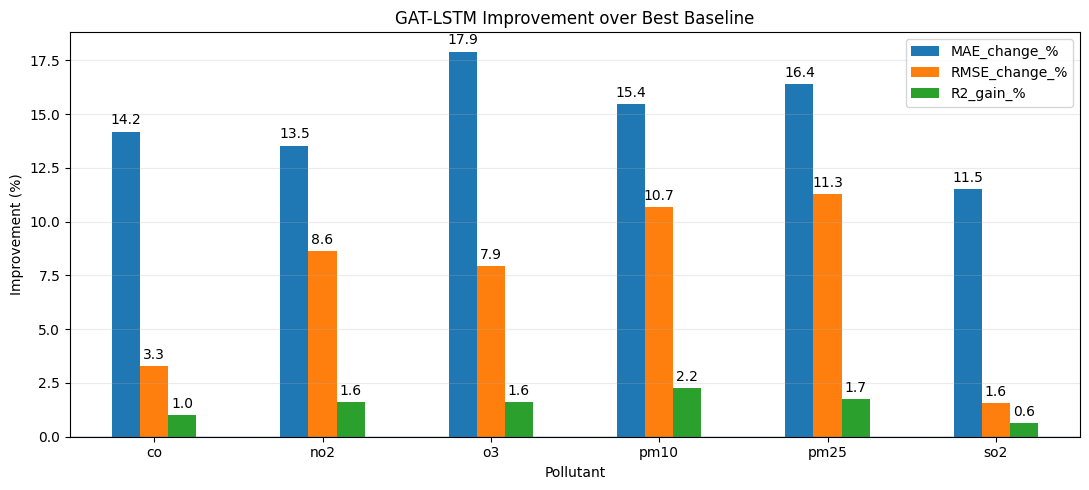

In [7]:
# ============================================================
# CELL 7 — GAT-LSTM Improvement
# ============================================================

rows = []

for p in TARGETS:
    b = poll[poll.Pollutant==p]
    g = b[b.Model=="GAT-LSTM"].iloc[0]
    base = b[b.Model!="GAT-LSTM"]

    rows.append({
        "Pollutant":p,
        "MAE_change_%":100*(base.MAE.min()-g.MAE)/base.MAE.min(),
        "RMSE_change_%":100*(base.RMSE.min()-g.RMSE)/base.RMSE.min(),
        "R2_gain_%":100*(g.R2-base.R2.max())/base.R2.max()
    })

imp = pd.DataFrame(rows).set_index("Pollutant")

ax = imp.plot(kind="bar",figsize=(11,5))
for c in ax.containers:
    ax.bar_label(c,fmt="%.1f",padding=3)

ax.axhline(0,linewidth=1)
ax.set_ylabel("Improvement (%)")
ax.set_title("GAT-LSTM Improvement over Best Baseline")
ax.tick_params(axis="x",rotation=0)
ax.grid(axis="y",alpha=.25)

plt.tight_layout()
plt.savefig(EXP_DIR/"fig6_gat_improvement.png",dpi=600,bbox_inches="tight")
plt.show()

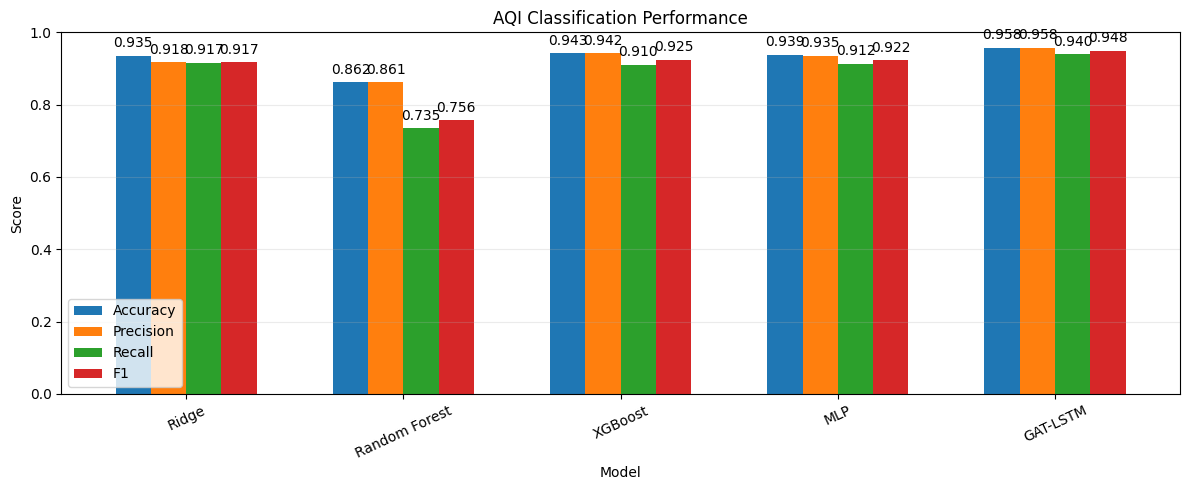

In [8]:
# ============================================================
# CELL 8 — AQI Classification
# ============================================================

aqi = summary.set_index("Model")[["Accuracy","Precision","Recall","F1"]].reindex(MODELS)

ax = aqi.plot(kind="bar",figsize=(12,5),width=.65)
for c in ax.containers:
    ax.bar_label(c,fmt="%.3f",padding=4)

ax.set_ylim(0,1)
ax.set_ylabel("Score")
ax.set_title("AQI Classification Performance")
ax.tick_params(axis="x",rotation=25)
ax.grid(axis="y",alpha=.25)

plt.tight_layout()
plt.savefig(EXP_DIR/"fig7_aqi_classification.png",dpi=400,bbox_inches="tight")
plt.show()

GAT-LSTM AQI CONFUSION MATRIX VALIDATION
Common windows: 84,014
Accuracy          : 0.957912 | PASS
Macro_precision   : 0.957895 | PASS
Macro_recall      : 0.939591 | PASS
Macro_F1          : 0.948343 | PASS


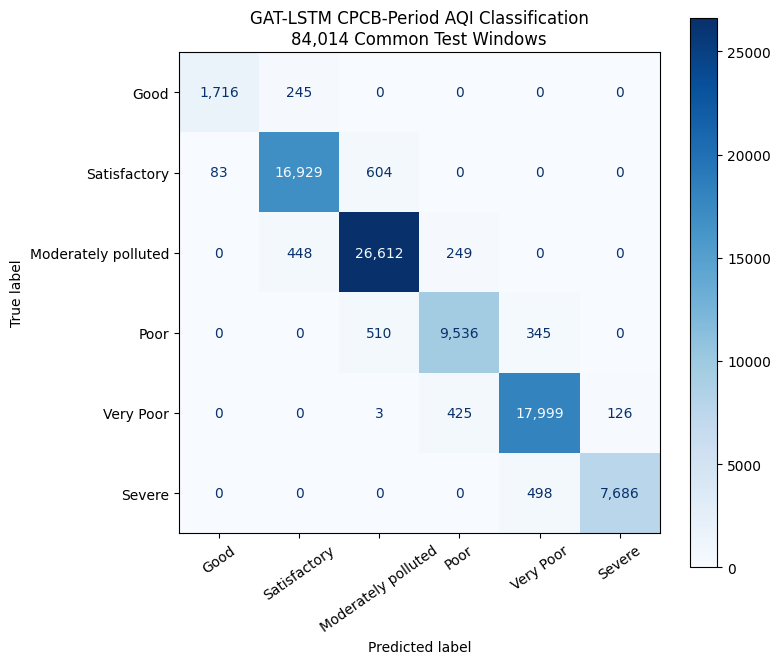


Saved confusion matrix: c:\Users\udish\College\MajorProjectSem7\Implementation\metrics\baseline_fulltrain\confusion_matrix_gat_lstm.csv
Saved figure: c:\Users\udish\College\MajorProjectSem7\Implementation\figures\exploratory\fig8_gat_aqi_confusion_matrix.png


In [9]:

# ============================================================
# CELL 9 — GAT-LSTM AQI Confusion Matrix
# Uses Notebook 6's final, common-window AQI table.
# ============================================================

from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
)

AQI_CATS = [
    "Good",
    "Satisfactory",
    "Moderately polluted",
    "Poor",
    "Very Poor",
    "Severe",
]

required_columns = [
    "datetime_utc",
    "location_id",
    "y_true_aqi",
    "y_pred_aqi__gat_lstm",
]

missing_columns = [
    col for col in required_columns
    if col not in aqi_windows.columns
]

if missing_columns:
    raise ValueError(
        f"Common AQI table is missing columns: {missing_columns}"
    )

if aqi_windows.duplicated(
    ["datetime_utc", "location_id"]
).any():
    raise ValueError(
        "Duplicate station-time windows found in the AQI table."
    )

y_true_aqi = aqi_windows["y_true_aqi"].astype(str)
y_pred_aqi = aqi_windows["y_pred_aqi__gat_lstm"].astype(str)

if not y_true_aqi.isin(AQI_CATS).all():
    raise ValueError(
        "The actual AQI categories include invalid or unexpected labels."
    )

if not y_pred_aqi.isin(AQI_CATS).all():
    raise ValueError(
        "The GAT-LSTM predicted AQI categories include invalid labels."
    )

if len(y_true_aqi) != 84014:
    raise ValueError(
        f"Expected 84,014 common classification windows; "
        f"found {len(y_true_aqi):,}."
    )

cm = confusion_matrix(
    y_true_aqi,
    y_pred_aqi,
    labels=AQI_CATS,
)

# Recalculate metrics directly from the same categories used
# in the confusion matrix.
gat_aqi_metrics = {
    "Accuracy": accuracy_score(y_true_aqi, y_pred_aqi),

    "Macro_precision": precision_score(
        y_true_aqi,
        y_pred_aqi,
        labels=AQI_CATS,
        average="macro",
        zero_division=0,
    ),

    "Macro_recall": recall_score(
        y_true_aqi,
        y_pred_aqi,
        labels=AQI_CATS,
        average="macro",
        zero_division=0,
    ),

    "Macro_F1": f1_score(
        y_true_aqi,
        y_pred_aqi,
        labels=AQI_CATS,
        average="macro",
        zero_division=0,
    ),
}

# Verify that these values agree with Notebook 6's saved
# GAT-LSTM classification results.
stored = aqi_common.loc[
    aqi_common["Model"] == "GAT-LSTM"
]

if len(stored) != 1:
    raise ValueError(
        "Expected exactly one GAT-LSTM row in the AQI metrics file."
    )

stored = stored.iloc[0]

metric_pairs = [
    ("Accuracy", "Accuracy"),
    ("Macro_precision", "Macro_precision"),
    ("Macro_recall", "Macro_recall"),
    ("Macro_F1", "Macro_F1"),
]

print("=" * 65)
print("GAT-LSTM AQI CONFUSION MATRIX VALIDATION")
print("=" * 65)
print("Common windows:", f"{len(y_true_aqi):,}")

for calculated_name, saved_name in metric_pairs:

    calculated = gat_aqi_metrics[calculated_name]
    saved = float(stored[saved_name])

    matches = np.isclose(
        calculated,
        saved,
        rtol=0,
        atol=1e-12,
    )

    print(
        f"{calculated_name:18s}: {calculated:.6f} | "
        f"{'PASS' if matches else 'CHECK'}"
    )

    if not matches:
        raise ValueError(
            f"{calculated_name} differs from Notebook 6's final result."
        )

# Save the confusion matrix as a CSV.
cm_df = pd.DataFrame(
    cm,
    index=[f"Actual_{c}" for c in AQI_CATS],
    columns=[f"Predicted_{c}" for c in AQI_CATS],
)

cm_output = BASELINE_METRICS_DIR / "confusion_matrix_gat_lstm.csv"
cm_df.to_csv(cm_output)

# Plot the matrix.
fig, ax = plt.subplots(figsize=(8, 7))

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=AQI_CATS,
).plot(
    ax=ax,
    values_format=",",
    cmap="Blues",
    colorbar=True,
    xticks_rotation=35,
)

ax.set_title(
    "GAT-LSTM CPCB-Period AQI Classification\n"
    "84,014 Common Test Windows"
)

plt.tight_layout()

fig_output = EXP_DIR / "fig8_gat_aqi_confusion_matrix.png"

plt.savefig(
    fig_output,
    dpi=400,
    bbox_inches="tight",
)

plt.show()

print("\nSaved confusion matrix:", cm_output)
print("Saved figure:", fig_output)


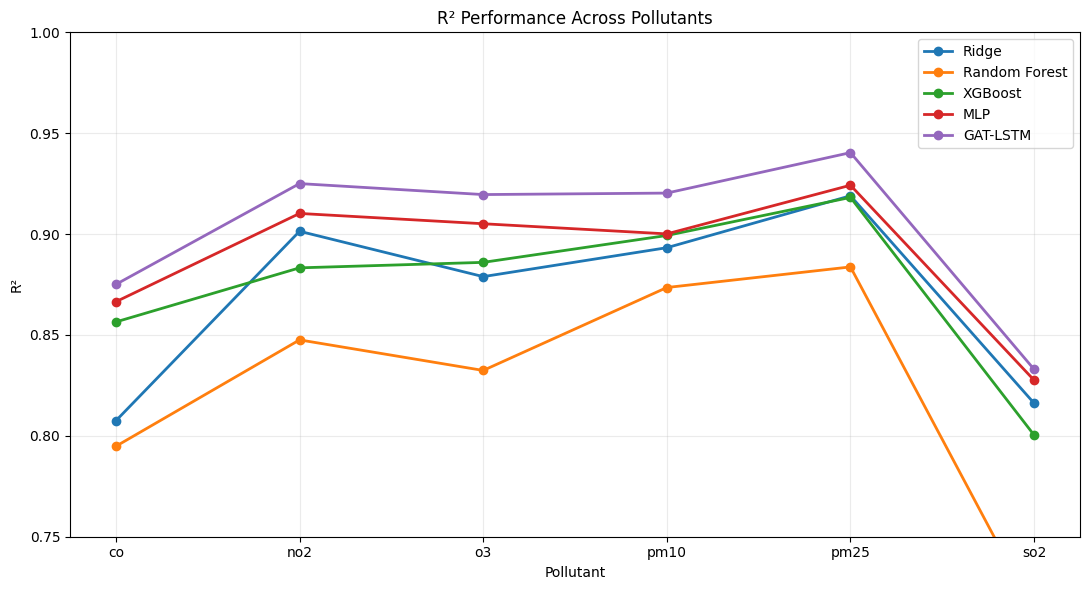

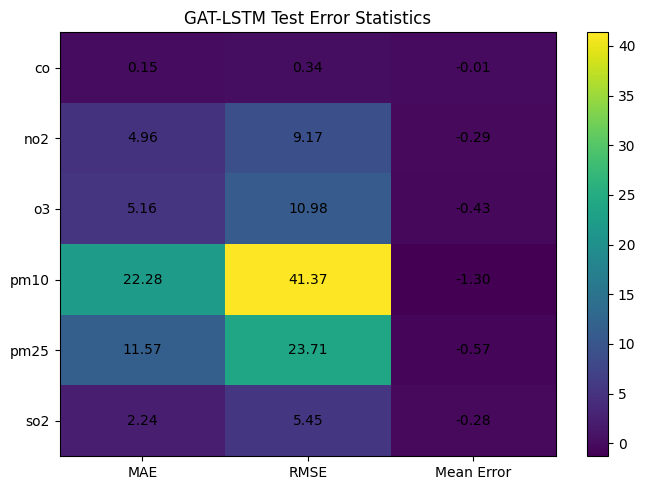

In [10]:
# ============================================================
# CELL 10 — R² Line + Error Heatmap
# ============================================================

plt.figure(figsize=(11,6))

for model in MODELS:
    d = poll[poll.Model==model].set_index("Pollutant").reindex(TARGETS)
    plt.plot(TARGETS,d["R2"],marker="o",linewidth=2,label=model)

plt.ylim(.75,1)
plt.xlabel("Pollutant")
plt.ylabel("R²")
plt.title("R² Performance Across Pollutants")
plt.grid(alpha=.25)
plt.legend()
plt.tight_layout()
plt.savefig(EXP_DIR/"fig9a_r2_line_comparison.png",dpi=400,bbox_inches="tight")
plt.show()

err = []

for k,p in enumerate(TARGETS):
    v = mask[:,:,k].astype(bool)
    r = (pred[:,:,k]-true[:,:,k])[v]
    err.append([np.mean(np.abs(r)),np.sqrt(np.mean(r**2)),np.mean(r)])

err = pd.DataFrame(err,index=TARGETS,columns=["MAE","RMSE","Mean Error"])

fig,ax = plt.subplots(figsize=(7,5))
im = ax.imshow(err.values,aspect="auto")
ax.set_xticks(range(3),err.columns)
ax.set_yticks(range(6),TARGETS)

for i in range(6):
    for j in range(3):
        ax.text(j,i,f"{err.iloc[i,j]:.2f}",ha="center",va="center")

ax.set_title("GAT-LSTM Test Error Statistics")
fig.colorbar(im,ax=ax)

plt.tight_layout()
plt.savefig(EXP_DIR/"fig11_error_heatmap.png",dpi=400,bbox_inches="tight")
plt.show()

In [11]:
# ============================================================
# CELL 11 — Graph Data
# ============================================================

stations = pd.read_csv(GRAPH_DIR/"station_metadata_final.csv")
edges = pd.read_csv(GRAPH_DIR/"edge_index_final.csv")

stations = stations.sort_values("location_id")
STATIONS = stations.location_id.tolist()

G = nx.Graph()
G.add_nodes_from(STATIONS)
G.add_edges_from(edges[["source","target"]].itertuples(index=False,name=None))

print("Stations:",len(stations))
print("Directed edges:",len(edges))
print("Undirected connections:",G.number_of_edges())
print("Connected components:",nx.number_connected_components(G))

Stations: 37
Directed edges: 169
Undirected connections: 110
Connected components: 1


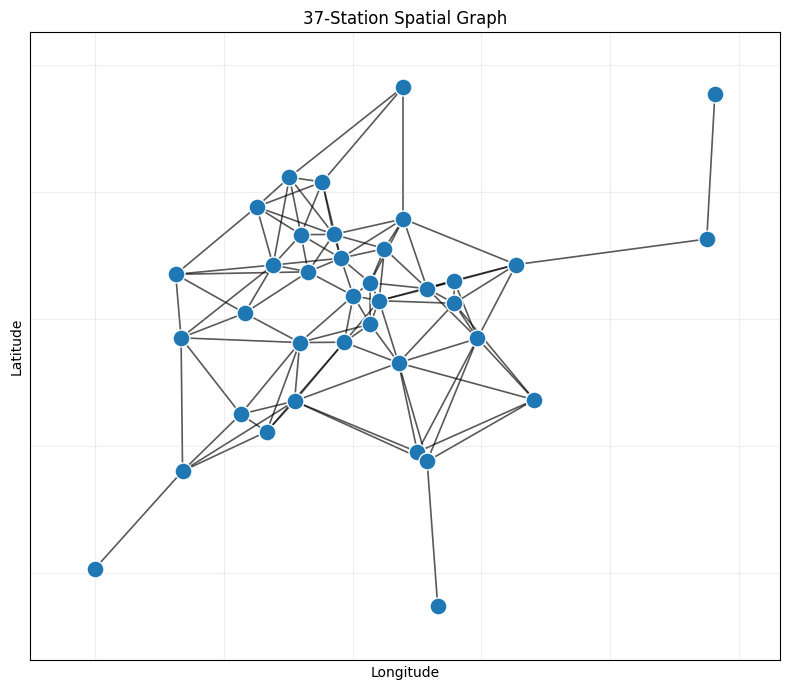

In [12]:
# ============================================================
# CELL 12 — Graph Structure
# ============================================================

pos = {r.location_id:(r.longitude,r.latitude) for _,r in stations.iterrows()}

fig,ax = plt.subplots(figsize=(8,7))
nx.draw_networkx_edges(G,pos,ax=ax,edge_color="black",alpha=.65,width=1.2)
nx.draw_networkx_nodes(G,pos,ax=ax,node_size=150,edgecolors="white",linewidths=1)

ax.set_title("37-Station Spatial Graph")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(alpha=.2)

plt.tight_layout()
plt.savefig(EXP_DIR/"fig12_graph_structure.png",dpi=400,bbox_inches="tight")
plt.show()

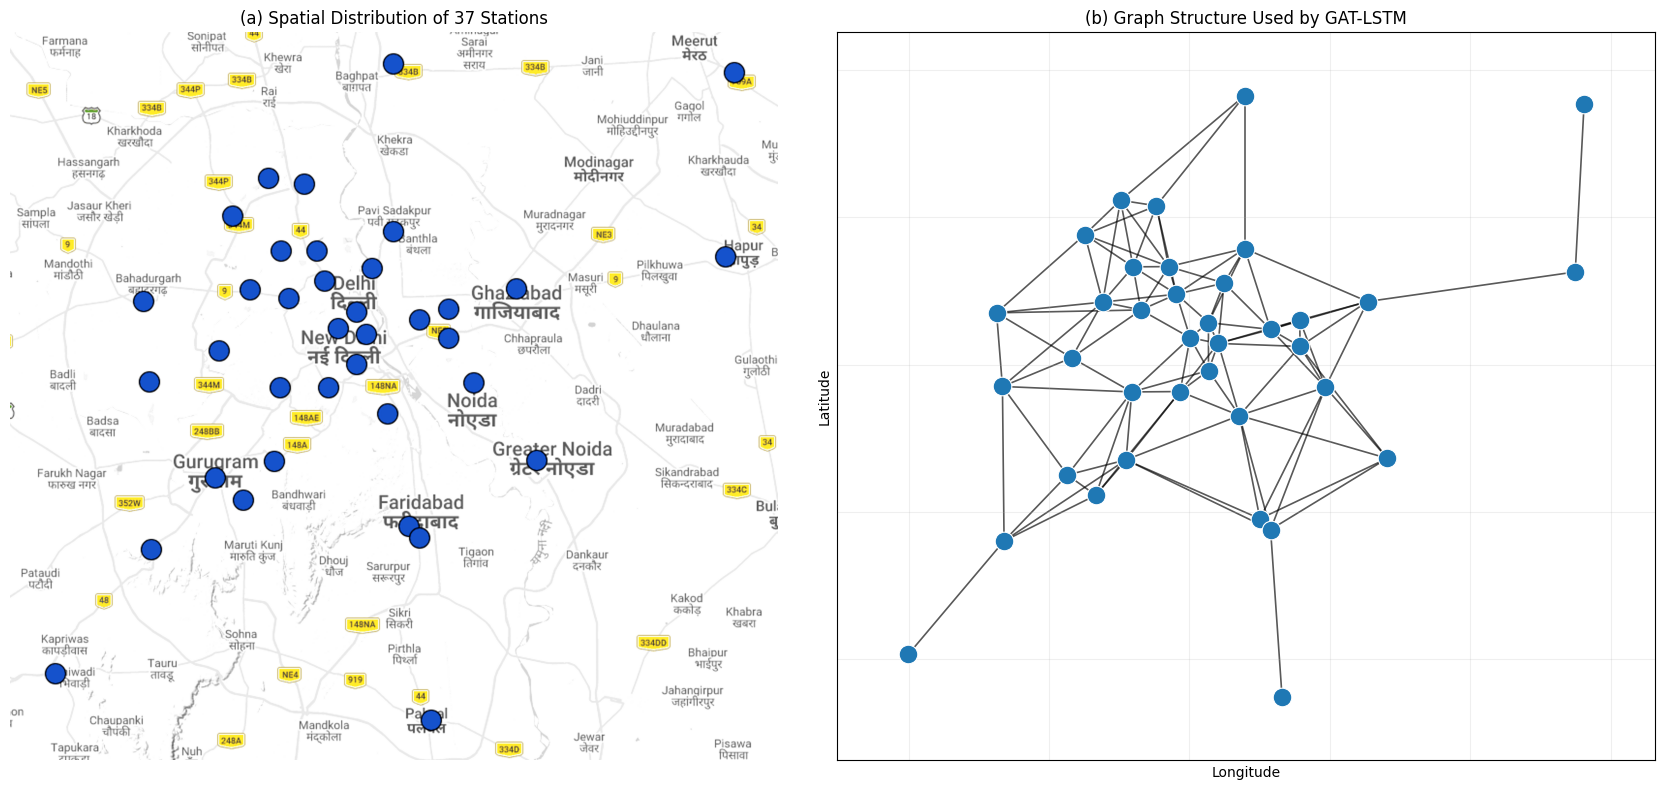

In [13]:
# ============================================================
# CELL 13 — Station Map + Graph
# ============================================================

MAP_FILE = EXP_DIR/"37StationsPlotted.png"
map_img = Image.open(MAP_FILE)

fig,(ax1,ax2) = plt.subplots(1,2,figsize=(17,8))

ax1.imshow(map_img)
ax1.set_title("(a) Spatial Distribution of 37 Stations")
ax1.axis("off")

nx.draw_networkx_edges(G,pos,ax=ax2,edge_color="black",alpha=.65,width=1.2)
nx.draw_networkx_nodes(G,pos,ax=ax2,node_size=180,edgecolors="white",linewidths=.8)

ax2.set_title("(b) Graph Structure Used by GAT-LSTM")
ax2.set_xlabel("Longitude")
ax2.set_ylabel("Latitude")
ax2.grid(alpha=.2)

plt.tight_layout()
plt.savefig(EXP_DIR/"fig1_station_map_and_graph.png",dpi=500,bbox_inches="tight")
plt.show()

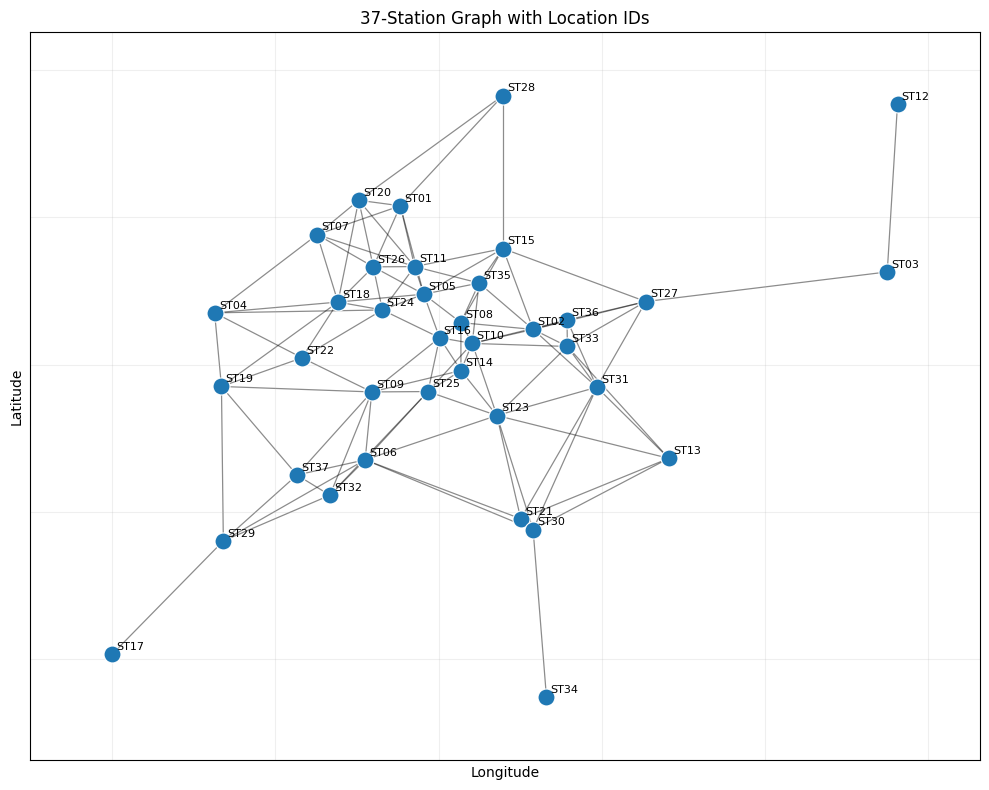

In [14]:
# ============================================================
# CELL 14 — Labeled Graph
# ============================================================

fig,ax = plt.subplots(figsize=(10,8))

nx.draw_networkx_edges(G,pos,ax=ax,edge_color="black",alpha=.45,width=.9)
nx.draw_networkx_nodes(G,pos,ax=ax,node_size=150,edgecolors="white",linewidths=.8)

for sid,(x,y) in pos.items():
    ax.annotate(sid,(x,y),xytext=(3,3),textcoords="offset points",fontsize=8)

ax.set_title("37-Station Graph with Location IDs")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.grid(alpha=.2)

plt.tight_layout()
plt.savefig(EXP_DIR/"fig13_labeled_station_graph.png",dpi=400,bbox_inches="tight")
plt.show()

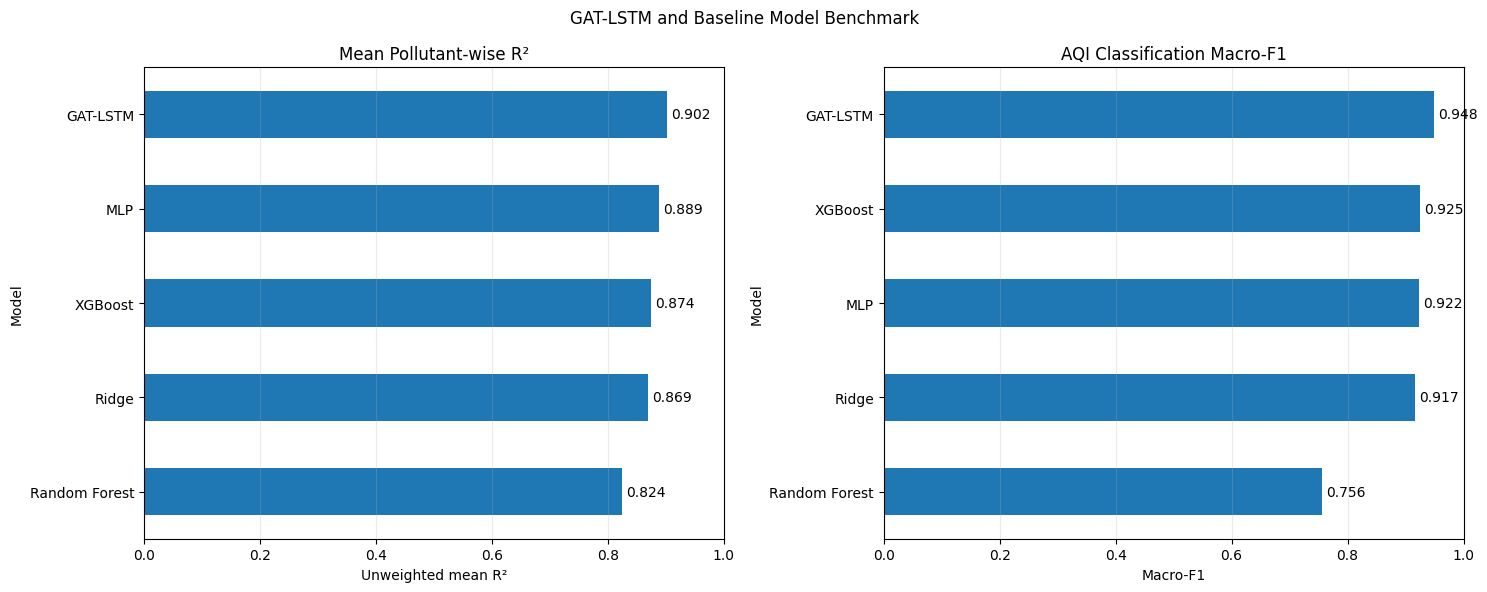

In [15]:

# ============================================================
# CELL 15 — Model Benchmark Comparison
# ============================================================

bench = summary.set_index("Model").reindex(MODELS)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

r2_values = bench["Mean_Pollutant_R2"].sort_values()
f1_values = bench["F1"].sort_values()

r2_values.plot(kind="barh", ax=ax1)
f1_values.plot(kind="barh", ax=ax2)

ax1.set_title("Mean Pollutant-wise R²")
ax1.set_xlabel("Unweighted mean R²")
ax1.set_xlim(0, 1)
ax1.grid(axis="x", alpha=0.25)

ax2.set_title("AQI Classification Macro-F1")
ax2.set_xlabel("Macro-F1")
ax2.set_xlim(0, 1)
ax2.grid(axis="x", alpha=0.25)

for ax in [ax1, ax2]:
    for container in ax.containers:
        ax.bar_label(container, fmt="%.3f", padding=3)

fig.suptitle("GAT-LSTM and Baseline Model Benchmark")
plt.tight_layout()

plt.savefig(
    EXP_DIR / "fig14_model_r2_aqi_f1_benchmark.png",
    dpi=400,
    bbox_inches="tight",
)

plt.show()


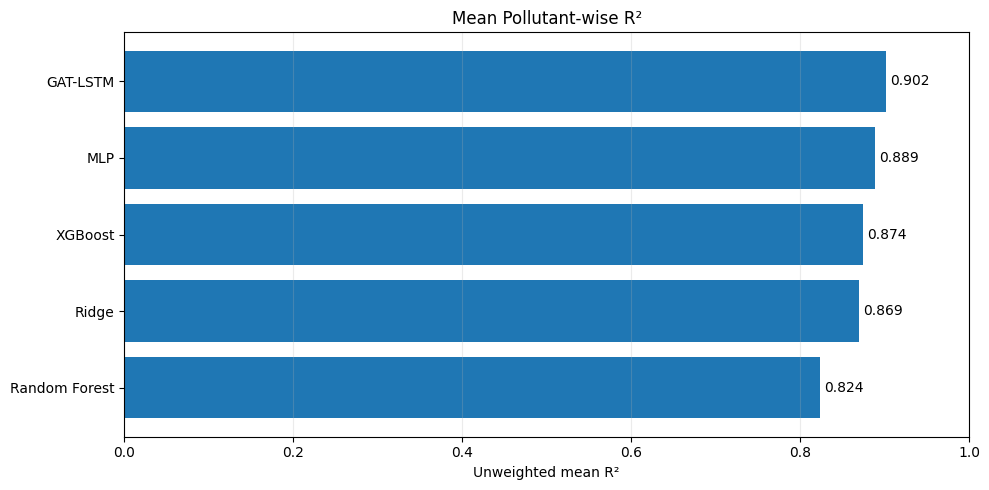

Saved: c:\Users\udish\College\MajorProjectSem7\Implementation\figures\exploratory\fig14a_model_mean_pollutant_r2.png


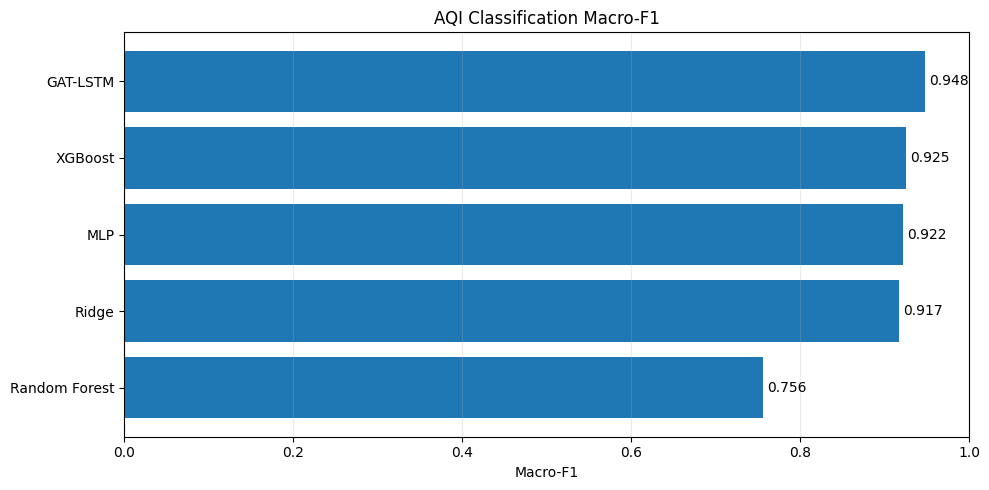

Saved: c:\Users\udish\College\MajorProjectSem7\Implementation\figures\exploratory\fig14b_model_aqi_macro_f1.png


In [16]:

# ============================================================
# CELL 16 — Separate Unitless Benchmark Figures
# ============================================================

bench = summary.set_index("Model").reindex(MODELS)

separate_metrics = [
    (
        "Mean_Pollutant_R2",
        "fig14a_model_mean_pollutant_r2.png",
        "Mean Pollutant-wise R²",
        "Unweighted mean R²",
    ),
    (
        "F1",
        "fig14b_model_aqi_macro_f1.png",
        "AQI Classification Macro-F1",
        "Macro-F1",
    ),
]

for metric, filename, title, xlabel in separate_metrics:

    values = bench[metric].sort_values()

    fig, ax = plt.subplots(figsize=(10, 5))

    bars = ax.barh(values.index, values.values)

    ax.bar_label(bars, fmt="%.3f", padding=3)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_xlim(0, 1)
    ax.grid(axis="x", alpha=0.25)

    plt.tight_layout()

    plt.savefig(
        EXP_DIR / filename,
        dpi=400,
        bbox_inches="tight",
    )

    plt.show()

    print("Saved:", EXP_DIR / filename)


In [17]:
# ============================================================
# CELL 17 — Detect Stations on Map
# ============================================================

img = Image.open(MAP_FILE).convert("RGB")
arr = np.asarray(img)
H,W = arr.shape[:2]

target = np.array([0x15,0x52,0xcc])
dist = np.sqrt(((arr.astype(int)-target)**2).sum(axis=2))
m = dist < 45

lab,n = label(m)
dots = []

for k in range(1,n+1):
    y,x = np.where(lab==k)
    if 300 < len(x) < 10000:
        dots.append((x.mean(),y.mean(),len(x)))

dots = np.array(dots)

print(f"Image: {W} × {H}")
print("Detected station dots:",len(dots))

Image: 3304 × 3133
Detected station dots: 37


In [18]:
# ============================================================
# CELL 18 — Match Stations to Map
# ============================================================

xy = stations[["longitude","latitude"]].to_numpy(float)

gx = (xy[:,0]-xy[:,0].min())/(xy[:,0].max()-xy[:,0].min())
gy = (xy[:,1]-xy[:,1].min())/(xy[:,1].max()-xy[:,1].min())

guess = np.column_stack([
    gx*(dots[:,0].max()-dots[:,0].min())+dots[:,0].min(),
    dots[:,1].max()-gy*(dots[:,1].max()-dots[:,1].min())
])

D = ((guess[:,None,:]-dots[None,:,:2])**2).sum(-1)
r,c = linear_sum_assignment(D)

pix = np.zeros((len(STATIONS),2))
pix[r] = dots[c,:2]

print("Stations:",len(STATIONS))
print("Edges:",len(edges))
print("Pixel matches:",len(pix))

Stations: 37
Edges: 169
Pixel matches: 37


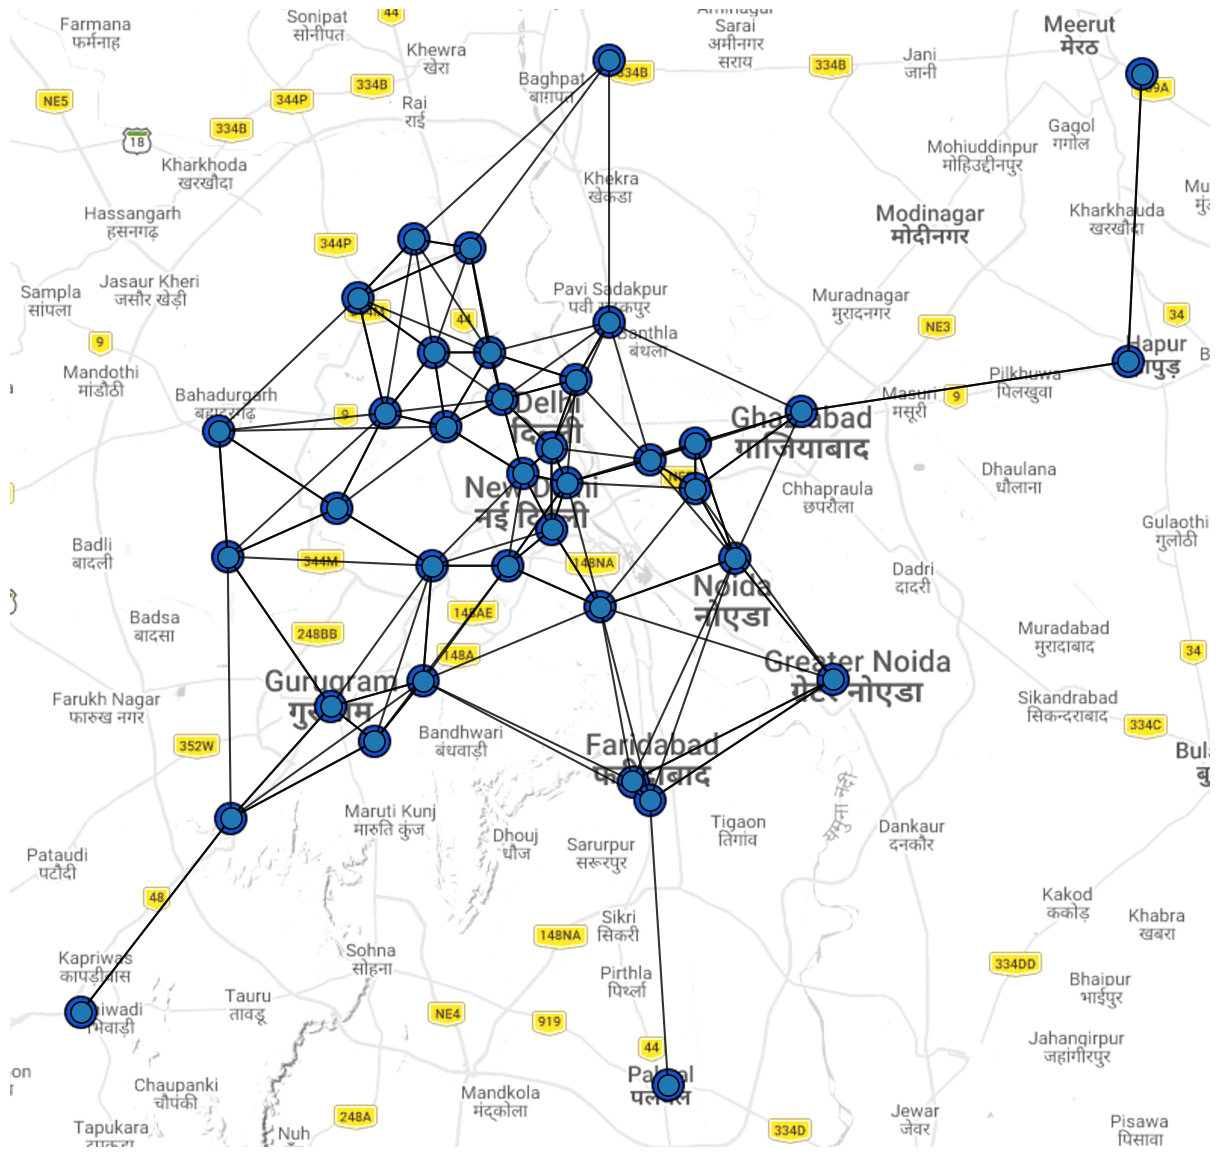

In [19]:
# ============================================================
# CELL 19 — Spatial Graph on Map
# ============================================================

fig,ax = plt.subplots(figsize=(12,12))
ax.imshow(img)

for _,e in edges.iterrows():
    i,j = STATIONS.index(e.source),STATIONS.index(e.target)
    ax.plot([pix[i,0],pix[j,0]],[pix[i,1],pix[j,1]],
            color="black",alpha=.8,linewidth=1.5)

ax.scatter(pix[:,0],pix[:,1],s=230,edgecolors="black",linewidths=1.2,zorder=3)

ax.set_xlim(0,W); ax.set_ylim(H,0); ax.axis("off")

plt.tight_layout(pad=0)
plt.savefig(EXP_DIR/"fig15_spatial_graph_on_map.png",dpi=500,bbox_inches="tight",pad_inches=.04)
plt.show()

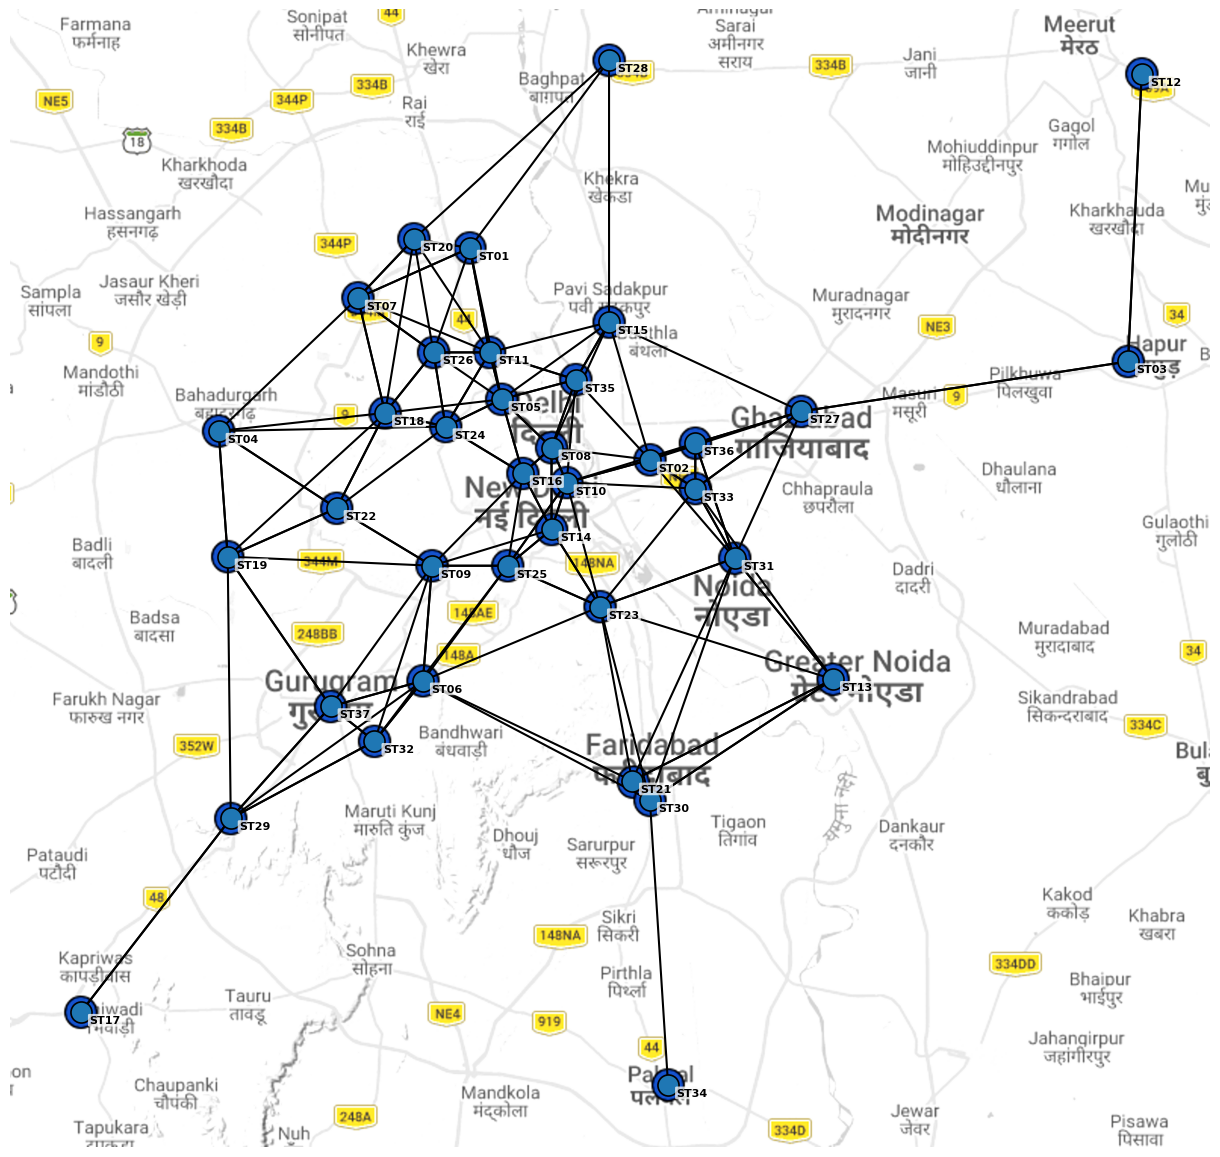

In [20]:
# ============================================================
# CELL 20 — Labeled Spatial Graph on Map
# ============================================================

fig,ax = plt.subplots(figsize=(12,12))
ax.imshow(img)

for _,e in edges.iterrows():
    i,j = STATIONS.index(e.source),STATIONS.index(e.target)
    ax.plot([pix[i,0],pix[j,0]],[pix[i,1],pix[j,1]],
            color="black",linewidth=1.5,zorder=2)

ax.scatter(pix[:,0],pix[:,1],s=230,edgecolors="black",linewidths=1.2,zorder=3)

for i,s in enumerate(STATIONS):
    ax.annotate(
        s,(pix[i,0],pix[i,1]),xytext=(6,-8),
        textcoords="offset points",fontsize=8,fontweight="bold",
        bbox=dict(boxstyle="round,pad=.12",facecolor="white",edgecolor="none",alpha=.75)
    )

ax.set_xlim(0,W); ax.set_ylim(H,0); ax.axis("off")

plt.tight_layout(pad=0)
plt.savefig(EXP_DIR/"fig16_labeled_spatial_graph_on_map.png",dpi=800,bbox_inches="tight",pad_inches=.04)
plt.show()

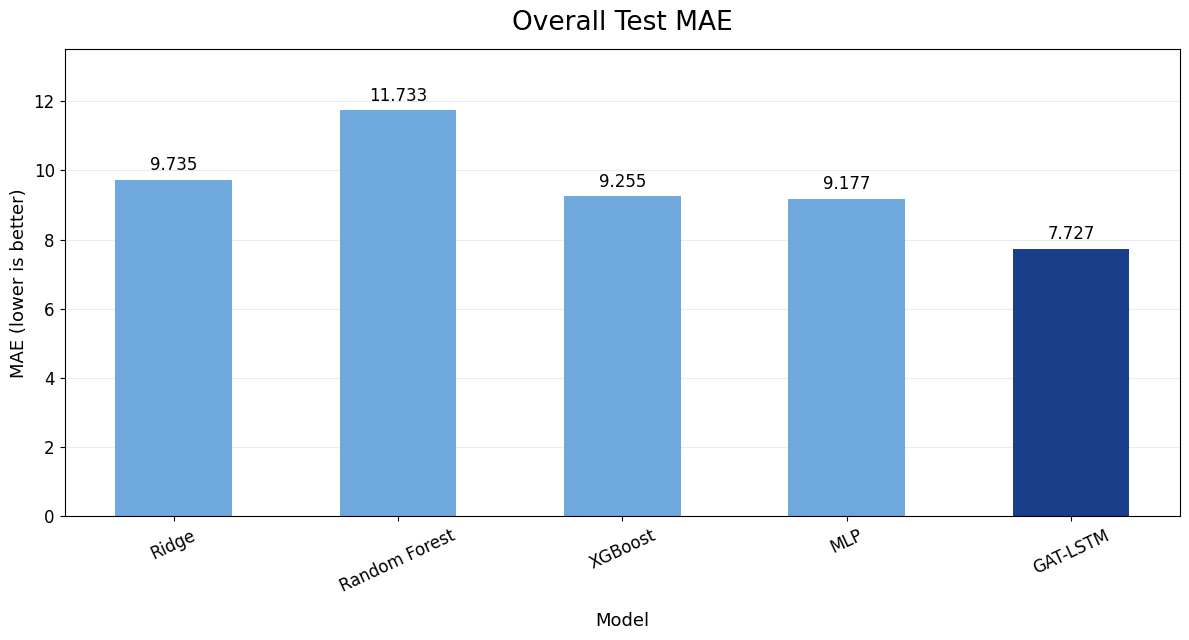

Mean pollutant-wise MAE:
Model
Ridge             9.7348
Random Forest    11.7331
XGBoost           9.2552
MLP               9.1769
GAT-LSTM          7.7270

Saved: c:\Users\udish\College\MajorProjectSem7\Implementation\figures\exploratory\baseline_mae_comparison.png


In [21]:

# ============================================================
# CELL 21 — Overall Test MAE Comparison
# ============================================================

MODEL_ORDER = [
    "Ridge",
    "Random Forest",
    "XGBoost",
    "MLP",
    "GAT-LSTM",
]

EXP_DIR.mkdir(parents=True, exist_ok=True)

# Unweighted mean of the six pollutant-specific MAE values.
mae_summary = (
    reg_common.groupby("Model")["MAE"]
    .mean()
    .reindex(MODEL_ORDER)
)

if mae_summary.isna().any():
    raise ValueError("Missing MAE results for one or more models.")

fig, ax = plt.subplots(figsize=(12, 6.5))

colors = [
    "#6FA8DC",
    "#6FA8DC",
    "#6FA8DC",
    "#6FA8DC",
    "#193F8A",
]

bars = ax.bar(
    mae_summary.index,
    mae_summary.values,
    color=colors,
    width=0.52,
)

ax.bar_label(
    bars,
    fmt="%.3f",
    padding=4,
    fontsize=12,
)

ax.set_title("Overall Test MAE", fontsize=19, pad=14)
ax.set_xlabel("Model", fontsize=13, labelpad=12)
ax.set_ylabel("MAE (lower is better)", fontsize=13)
ax.tick_params(axis="x", labelrotation=25, labelsize=12)
ax.tick_params(axis="y", labelsize=12)
ax.set_ylim(0, max(mae_summary.values) * 1.15)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

plt.tight_layout()

mae_fig_path = EXP_DIR / "baseline_mae_comparison.png"

plt.savefig(
    mae_fig_path,
    dpi=400,
    bbox_inches="tight",
)

plt.show()

print("Mean pollutant-wise MAE:")
print(mae_summary.round(4).to_string())
print("\nSaved:", mae_fig_path)


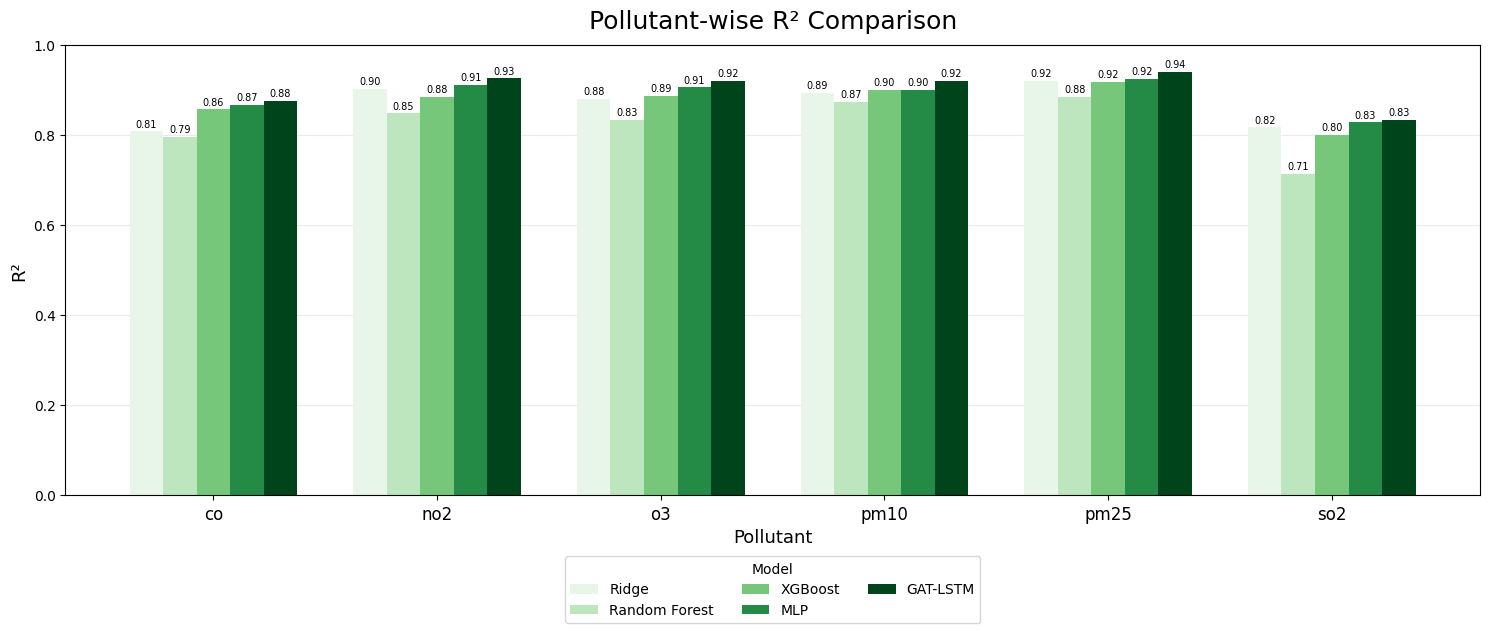

Pollutant-wise R² values:


Model,Ridge,Random Forest,XGBoost,MLP,GAT-LSTM
Pollutant,,,,,
co,0.8075,0.7948,0.8565,0.8665,0.8751
no2,0.9014,0.8476,0.8833,0.9102,0.9250
o3,0.8789,0.8324,0.8860,0.9051,0.9196
pm10,0.8933,0.8735,0.8993,0.9001,0.9203
pm25,0.9190,0.8837,0.9182,0.9242,0.9404
so2,0.8162,0.7128,0.8004,0.8276,0.8330



Saved: c:\Users\udish\College\MajorProjectSem7\Implementation\figures\exploratory\pollutant_wise_r2_comparison.png


In [22]:

# ============================================================
# CELL 22 — Pollutant-wise R² Comparison
# ============================================================

MODEL_ORDER = [
    "Ridge",
    "Random Forest",
    "XGBoost",
    "MLP",
    "GAT-LSTM",
]

TARGET_ORDER = [
    "co",
    "no2",
    "o3",
    "pm10",
    "pm25",
    "so2",
]

# Rows = pollutants, columns = models.
r2_table = reg_common.pivot(
    index="Pollutant",
    columns="Model",
    values="R2",
).reindex(index=TARGET_ORDER, columns=MODEL_ORDER)

if r2_table.isna().any().any():
    raise ValueError(
        "R² comparison has missing model-pollutant results."
    )

fig, ax = plt.subplots(figsize=(15, 6.5))

x = np.arange(len(TARGET_ORDER))
width = 0.15

colors = [
    "#E8F5E9",
    "#BDE5BE",
    "#76C779",
    "#238B45",
    "#00441B",
]

for i, model_name in enumerate(MODEL_ORDER):

    offset = (i - (len(MODEL_ORDER) - 1) / 2) * width

    bars = ax.bar(
        x + offset,
        r2_table[model_name].to_numpy(),
        width=width,
        label=model_name,
        color=colors[i],
    )

    # Display R² above every bar
    ax.bar_label(
        bars,
        fmt="%.2f",
        padding=2,
        fontsize=7,
        rotation=0,
    )

ax.set_title(
    "Pollutant-wise R² Comparison",
    fontsize=18,
    pad=12,
)

ax.set_xlabel("Pollutant", fontsize=13)
ax.set_ylabel("R²", fontsize=13)

ax.set_xticks(x)
ax.set_xticklabels(TARGET_ORDER, fontsize=12)

ax.set_ylim(0, 1.0)
ax.grid(axis="y", alpha=0.25)
ax.set_axisbelow(True)

ax.legend(
    title="Model",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=3,
    frameon=True,
)

plt.tight_layout()

r2_fig_path = EXP_DIR / "pollutant_wise_r2_comparison.png"

plt.savefig(
    r2_fig_path,
    dpi=600,
    bbox_inches="tight",
)

plt.show()

print("Pollutant-wise R² values:")
display(r2_table.round(4))

print("\nSaved:", r2_fig_path)


In [23]:
# ============================================================
# CELL 23 — Final Visualization Audit
# ============================================================

print("="*60)
print("FINAL VISUALIZATION AUDIT")
print("="*60)
print("Models:",MODELS)
print("Stations:",len(stations))
print("Directed edges:",len(edges))
print("Graph connected:",nx.number_connected_components(G)==1)
print("GAT predictions:",pred.shape)
print("GAT targets:",true.shape)
print("Exploratory figures:",len(list(EXP_DIR.glob("*.png"))))
print("Output folder:",EXP_DIR)

FINAL VISUALIZATION AUDIT
Models: ['Ridge', 'Random Forest', 'XGBoost', 'MLP', 'GAT-LSTM']
Stations: 37
Directed edges: 169
Graph connected: True
GAT predictions: (6550, 37, 6)
GAT targets: (6550, 37, 6)
Exploratory figures: 21
Output folder: c:\Users\udish\College\MajorProjectSem7\Implementation\figures\exploratory
